In [ ]:
# IMPORTS -------------------------------------------------------------------- #
import os
import sys
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns

import myutils

workspace,experiment=myutils.workspace()

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import scanpy as sc

In [37]:
# verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.verbosity = 3
sc.set_figure_params(dpi=80,facecolor='white', frameon=True, dpi_save=150, scanpy=True, fontsize=14, transparent=False, color_map=None)

In [38]:
result_dir = experiment/'results/scanpy_workflow'
data_file = result_dir/'pbmc3k_sc_norm.h5ad'
result_file = result_dir/'pbmc3k_scanpy_annotated.h5ad'

In [39]:
adata = sc.read(data_file)
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'scrublet'
    layers: 'counts', None (.X)

# Prep

In [40]:
adata.layers["scaled"] = adata.X.toarray()
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"], layer="scaled")
sc.pp.scale(adata, max_value=10, layer="scaled")


regressing out ['total_counts', 'pct_counts_mt']
    finished (0:00:01)


# PCA

In [41]:
sc.tl.pca(adata, layer='scaled', n_comps=50, zero_center=True, mask_var="highly_variable", svd_solver='arpack')

computing PCA
    with n_comps=50
    finished (0:00:38)


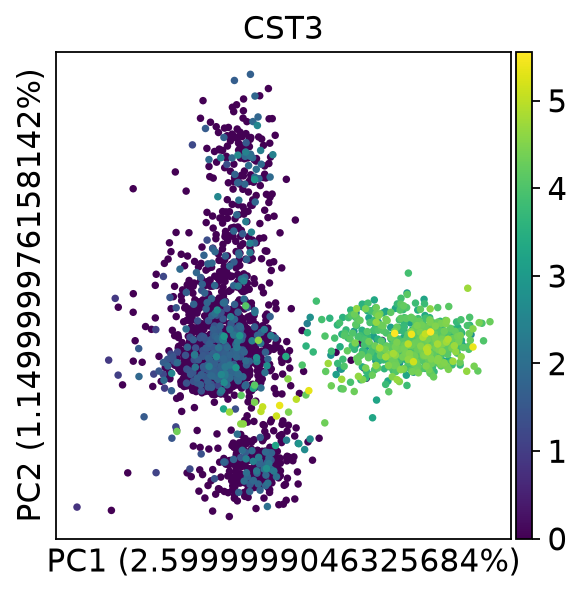

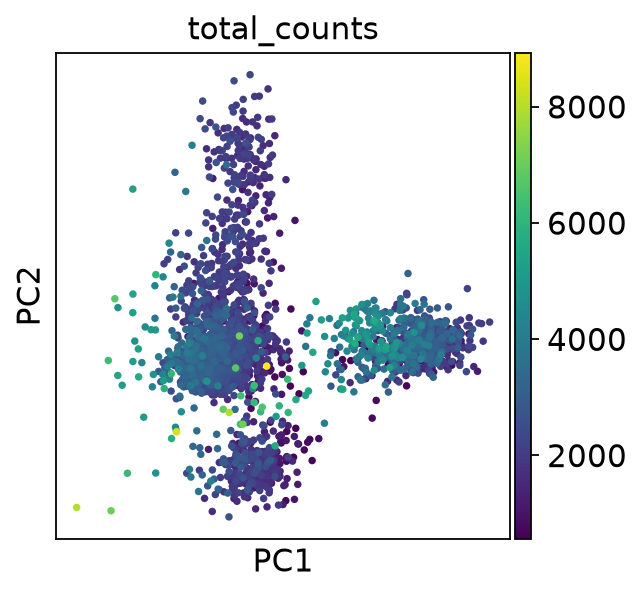

In [42]:
sc.pl.pca(adata, annotate_var_explained=True, color="CST3")
sc.pl.pca(adata, color="total_counts")

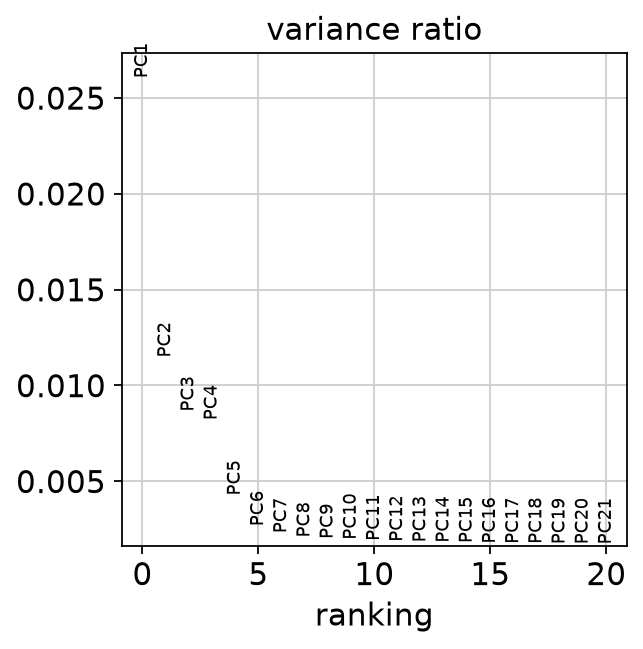

In [43]:
sc.pl.pca_variance_ratio(adata, n_pcs=20)
pca_n = 10

# Neighborhood graph

In [44]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=pca_n, use_rep='X_pca')

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)


In [45]:
sc.settings.verbosity = 3
RES=0.3
sc.tl.leiden(adata, flavor='igraph',resolution=RES,random_state=0,n_iterations=2,directed=False)

running Leiden clustering
    finished: found 8 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


In [46]:
sc.tl.paga(adata)
sc.pl.paga(adata, plot=False)


running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:00)
--> added 'pos', the PAGA positions (adata.uns['paga'])


computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


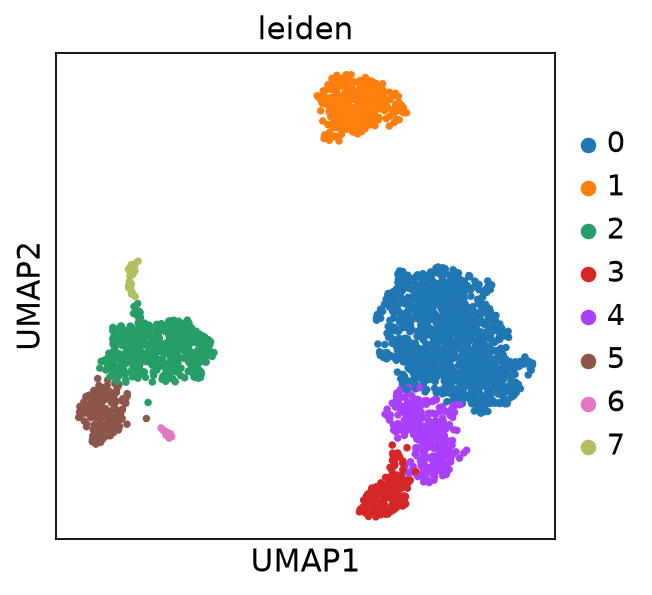

In [47]:
sc.tl.umap(adata)
sc.pl.umap(adata, color="leiden")

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


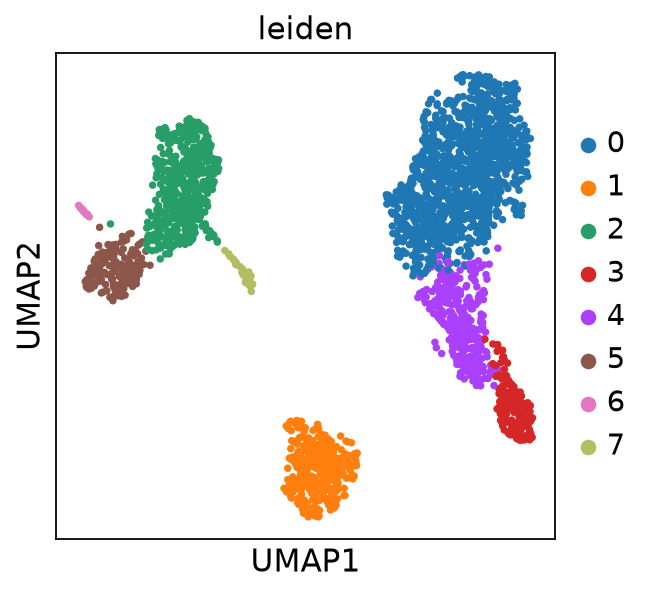

In [48]:
sc.tl.umap(adata, init_pos='paga')
fig = sc.pl.umap(adata, color="leiden", show=False)
plt.savefig(experiment/f'figures/clustering/scanpy_workflow/leiden_{pca_n}PCA_{RES}res_umap.png')

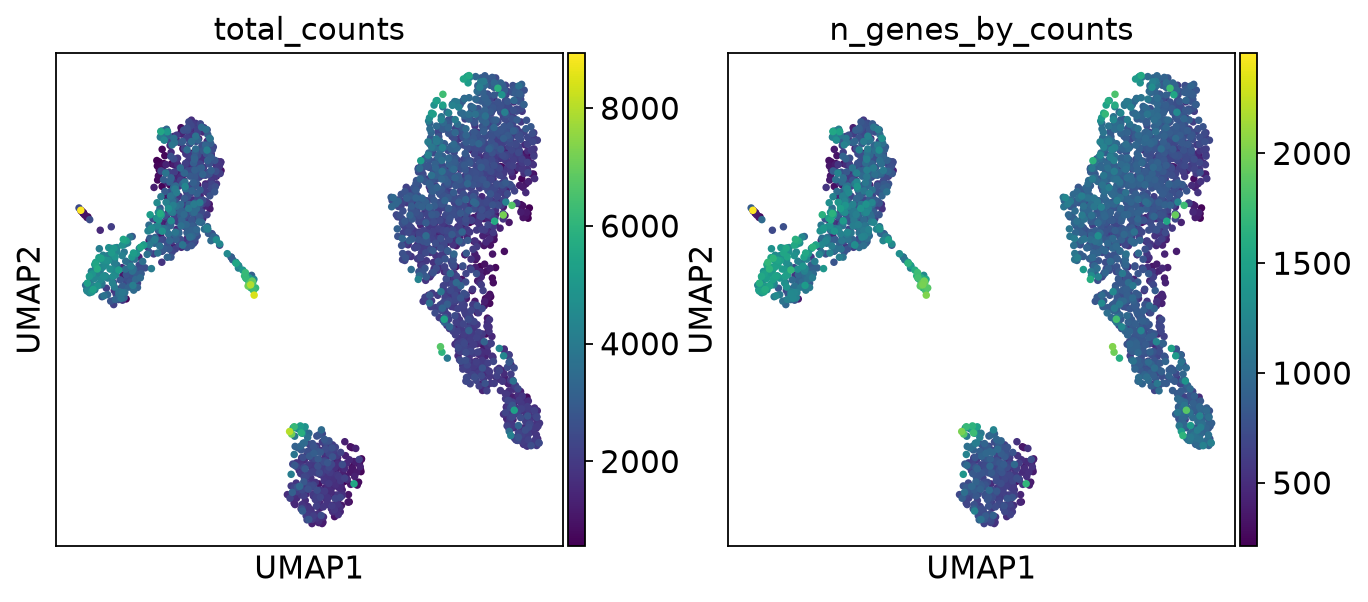

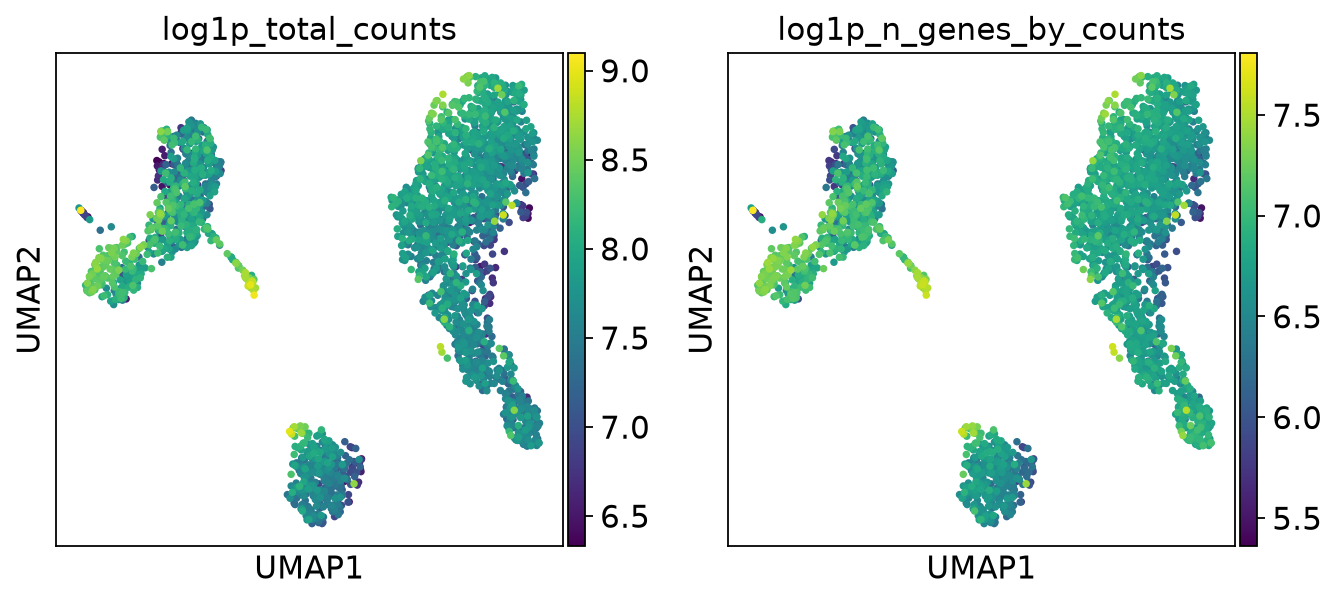

In [49]:
# UMAP QC METRICS ------------------------------------------------------------ #
sc.pl.umap(adata, color=["total_counts",'n_genes_by_counts'])
sc.pl.umap(adata, color=["log1p_total_counts",'log1p_n_genes_by_counts'])

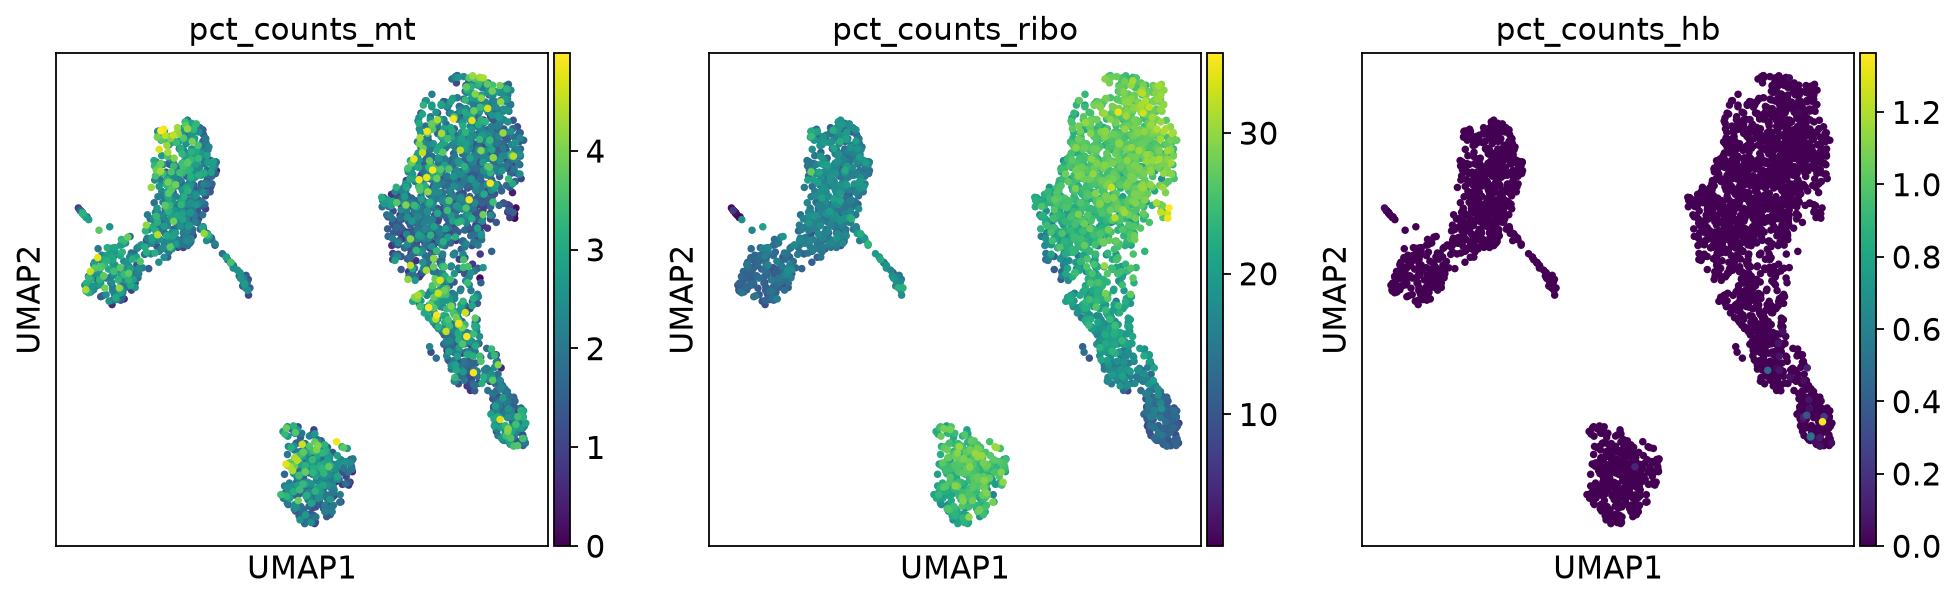

In [50]:
# UMAP QC METRICS ------------------------------------------------------------ #
sc.pl.umap(adata, color=['pct_counts_mt','pct_counts_ribo','pct_counts_hb'])
# sc.pl.umap(adata, color=['outlier','predicted_doublet'])

# Marker genes

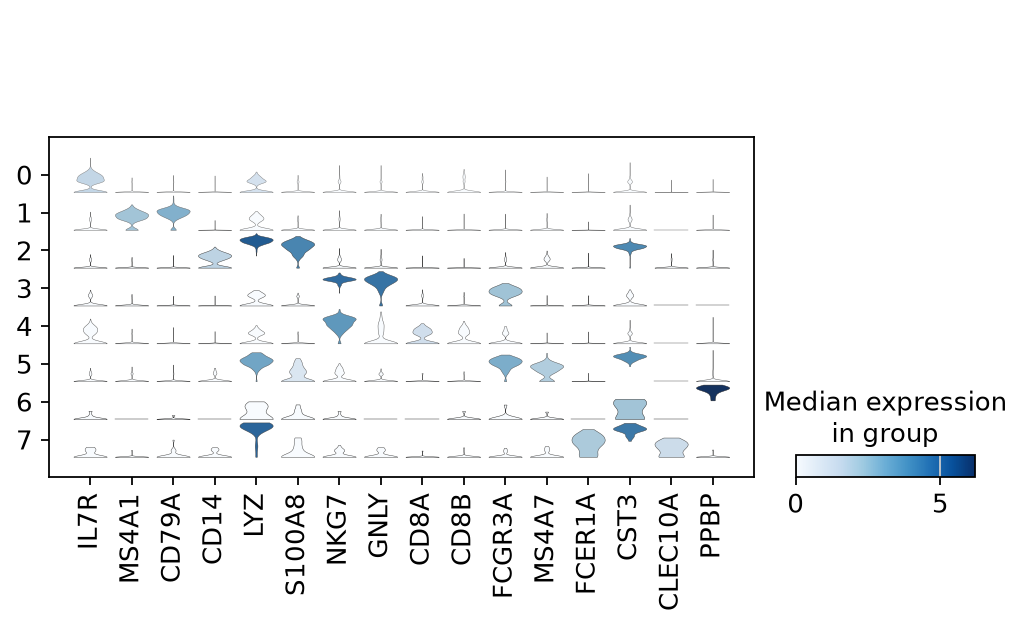

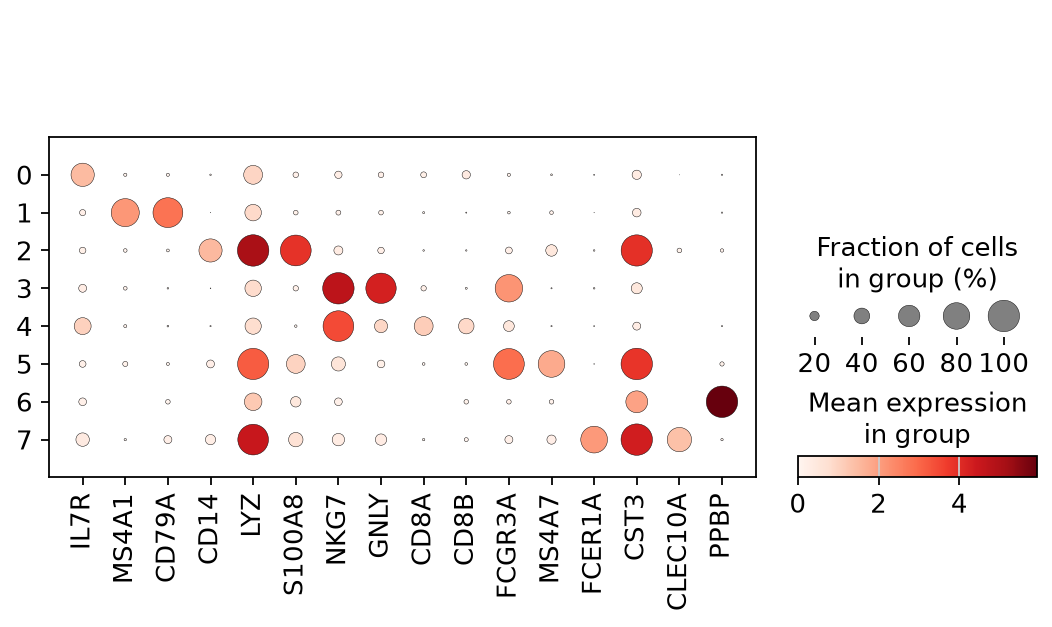

In [51]:
# SOME MARKER GENES ---------------------------------------------------------- #
# IL7R - CD4 T cells
# MS4A1 - B cells
# CD14, LYZ - CD14+ Monocytes
# CD8A - CD8 T cells
# GNLY, NKG7 - NK cells
# FCGR3A, MS4A7 - FCGR3A+ Monocytes
# FCER1A, CST3 - Dendritic Cells
# PPBP - Megakaryocytes
# ---------------------------------------------------------------------------- #
marker_genes = [
    *["IL7R", "CD79A", "MS4A1", "CD8A", "CD8B", "LYZ", "CD14"],
    *["LGALS3", "S100A8", "GNLY", "NKG7", "KLRB1"],
    *["FCGR3A", "MS4A7", "FCER1A", "CST3", "PPBP"],
]

marker_genes = {
    "CD4 T" : ['IL7R'],
    "B" : ['MS4A1','CD79A'],
    "CD14+ Monocytes" : ['CD14','LYZ','S100A8'],
    "NK" : ['NKG7','GNLY'],
    "CD8 T" : ['CD8A','CD8B'],
    "FCGR3A+ Monocytes" : ['FCGR3A','MS4A7'],
    "Dendritic" : ['FCER1A','CST3','CLEC10A'],
    "Megakaryocytes" : ['PPBP'],
    # "More" : ['LGALS3','KLRB1']
}

sc.set_figure_params(scanpy=True)
sc.pl.stacked_violin(adata, [g for v in marker_genes.values() for g in v], groupby="leiden",dodge=False)
sc.pl.dotplot(adata, [g for v in marker_genes.values() for g in v], groupby="leiden")


In [52]:
adata_annot = adata.copy()
for celltype,genes in marker_genes.items():
    sc.tl.score_genes(adata_annot, gene_list=genes, score_name=celltype,)

markers = adata_annot.obs.groupby('leiden')[list(marker_genes.keys())].mean()


computing score 'CD4 T'
    finished: added
    'CD4 T', score of gene set (adata.obs).
    50 total control genes are used. (0:00:00)
computing score 'B'
    finished: added
    'B', score of gene set (adata.obs).
    50 total control genes are used. (0:00:00)
computing score 'CD14+ Monocytes'
    finished: added
    'CD14+ Monocytes', score of gene set (adata.obs).
    100 total control genes are used. (0:00:00)
computing score 'NK'
    finished: added
    'NK', score of gene set (adata.obs).
    100 total control genes are used. (0:00:00)
computing score 'CD8 T'
    finished: added
    'CD8 T', score of gene set (adata.obs).
    50 total control genes are used. (0:00:00)
computing score 'FCGR3A+ Monocytes'
    finished: added
    'FCGR3A+ Monocytes', score of gene set (adata.obs).
    98 total control genes are used. (0:00:00)
computing score 'Dendritic'
    finished: added
    'Dendritic', score of gene set (adata.obs).
    150 total control genes are used. (0:00:00)
computing scor

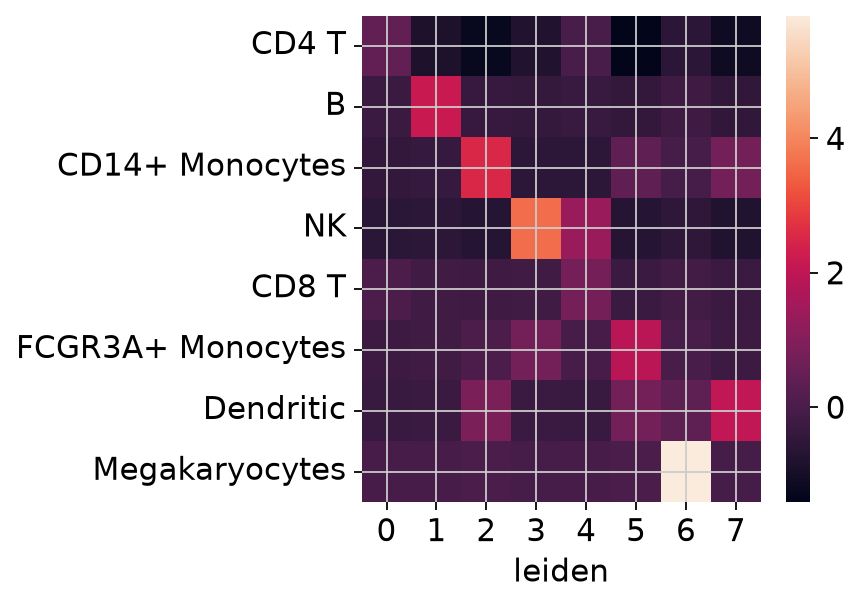

In [53]:
sns.heatmap(markers.T)
plt.show()

In [54]:
# CELLTYPES BASED ON SC.TL.SCORE_GENES --------------------------------------- #
sc.settings.verbosity = 1

def find_optimum(gene_scores,group,idx=0):
    prediction = gene_scores.loc[group].sort_values(ascending=False).index[idx]
    confirm =  markers[prediction].sort_values(ascending=False).index[0]
    if confirm == group:
        return prediction
    else:
        return find_optimum(gene_scores,group,idx=idx+1)

new_names = {gr: find_optimum(markers,gr) for gr in adata_annot.obs.leiden.cat.categories}
print('\n'.join([f'{k} : {v}' for k,v in new_names.items()]))

0 : CD4 T
1 : B
2 : CD14+ Monocytes
3 : NK
4 : CD8 T
5 : FCGR3A+ Monocytes
6 : Megakaryocytes
7 : Dendritic


In [55]:
# COMPARE ONE AGAINST ALL ---------------------------------------------------- #

sc.tl.rank_genes_groups(
    adata_annot, 
    groupby="leiden",
    # mask_var="highly_variable", 
    method="wilcoxon",
    groups='all',
    reference='rest'
    )

# compare on leiden group vs rest
# 
rank_genes_groups_df = {}
for group in adata_annot.obs.leiden.cat.categories:
    df = sc.get.rank_genes_groups_df(adata_annot,group=group)
    rank_genes_groups_df[group] = df

# CELLTYPES BASED ON SC.TL.RANK_GENES_GROUPS --------------------------------- #

scores = {}
combined_df=[]
for celltype, genes in marker_genes.items():
    scores[celltype] = {}
    predicted = []
    for gene in genes:
        score_list = []
        # rank of gene (in marker genes of cell type) for each leiden group = score_list
        for gr in rank_genes_groups_df:
            score = rank_genes_groups_df[gr].query('names == @gene').scores.values
            if len(score)==1: score = score[0]
            elif len(score)==0: score = None
            else: print(gene,score)
            row = {'gene':gene,'group':gr,'score':score}
            score_list.append(row)
        df = pd.DataFrame(score_list)
        df_gene_score = df.copy().rename(columns={'score':f'{gene}'})
        scores[celltype][gene] = df_gene_score
        combined_df.append(df_gene_score[f'{gene}'])
        # score is over 0 = leiden group could be cell type
        predicted.append(str(df.query('score > 0').sort_values('score',ascending=False).index[0]))
    df_scores = [scores[celltype][gene][[f'{gene}']] for gene in scores[celltype]]
    df_scores = pd.concat(df_scores,axis=1)
    # group with highest score / highest mean score over multiple genes wins
    prediction = df_scores.mean(axis=1).sort_values(ascending=False).index[0]
    print(f'{prediction} : {celltype}', set(predicted), genes)
combined_df = pd.concat(combined_df,axis=1)

0 : CD4 T {'0'} ['IL7R']
1 : B {'1'} ['MS4A1', 'CD79A']
2 : CD14+ Monocytes {'2'} ['CD14', 'LYZ', 'S100A8']
3 : NK {'4', '3'} ['NKG7', 'GNLY']
4 : CD8 T {'4'} ['CD8A', 'CD8B']
5 : FCGR3A+ Monocytes {'5'} ['FCGR3A', 'MS4A7']
2 : Dendritic {'7', '2'} ['FCER1A', 'CST3', 'CLEC10A']
6 : Megakaryocytes {'6'} ['PPBP']


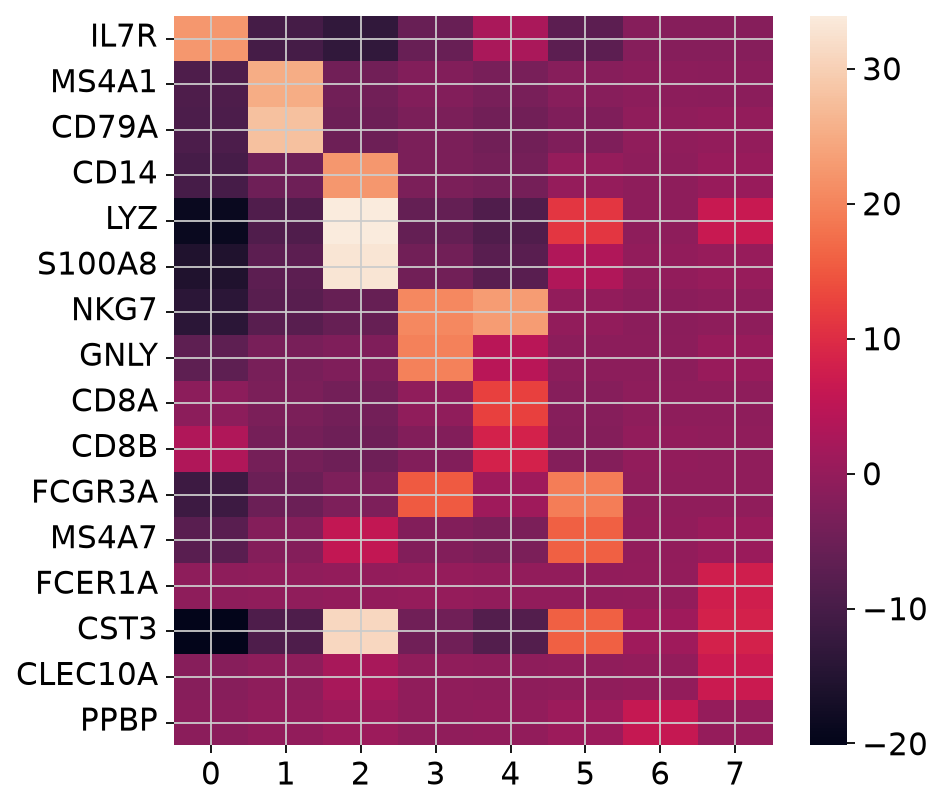

In [56]:
n_rows = len(combined_df)
plt.figure(figsize=(6, max(6, n_rows * 0.25)))
sns.heatmap(combined_df.T)
plt.show()

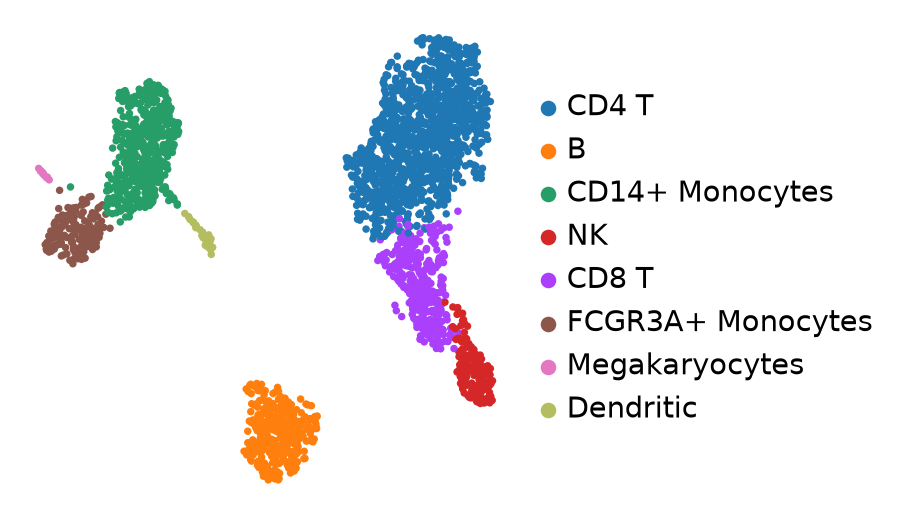

In [57]:
# RENAME LEIDEN CLUSTERS ----------------------------------------------------- #
adata.obs['celltype'] = adata.obs['leiden']
adata.rename_categories('celltype',list(new_names.values()))
sc.pl.umap(adata, color="celltype", title="", frameon=False)

# Save data

In [58]:
adata.write(result_file)
